# Деревья решений на данных Titanic

In [1]:
# Окружение и версии. Фиксируем сиды (random_state=17 везде ниже — воспроизводимость),
# глушим UserWarning pandas/sklearn, печатаем версии (важно: API get_dummies/drop — pandas 3.x).
import warnings
warnings.filterwarnings("ignore")  # чистый вывод без UserWarning библиотек
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import GridSearchCV, cross_val_score

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", matplotlib.__version__)
import sklearn
print("sklearn", sklearn.__version__)

numpy 2.4.6
pandas 3.1.0
matplotlib 3.11.2
sklearn 1.9.1


## 1. Загрузка данных
Классический Kaggle Titanic: `titanic_train.csv` (891 строка, есть `Survived`) и `titanic_test.csv` (418 строк, без метки).

In [2]:
# Загрузка. train — обучающая выборка (есть целевая метка Survived), test — без неё.
# y отделяем сразу: это вектор ответов для обучения.
train_df = pd.read_csv("titanic_train.csv")  # 891 строка
test_df = pd.read_csv("titanic_test.csv")  # 418 строк
y = train_df["Survived"]  # целевая переменная: 0 — погиб, 1 — выжил
print("train:", train_df.shape, " test:", test_df.shape)
print(train_df.head(3).to_string())
print("Пропуски в train:")
print(train_df.isna().sum()[train_df.isna().sum() > 0])
print("Пропуски в test:")
print(test_df.isna().sum()[test_df.isna().sum() > 0])

train: (891, 12)  test: (418, 11)
   PassengerId  Survived  Pclass                                                 Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
0            1         0       3                              Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
1            2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Thayer)  female  38.0      1      0          PC 17599  71.2833   C85        C
2            3         1       3                               Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
Пропуски в train:
Age         177
Cabin       687
Embarked      2
dtype: int64
Пропуски в test:
Age       86
Fare       1
Cabin    327
dtype: int64


## 2. Заполнение пропусков
Как в примере из задания: `Age` — медианой (для test — медианой train), `Embarked` — модой `'S'`, `Fare` в test — медианой train.

age_median = 28.0  fare_median = 14.4542
Пропусков после заполнения: 1014


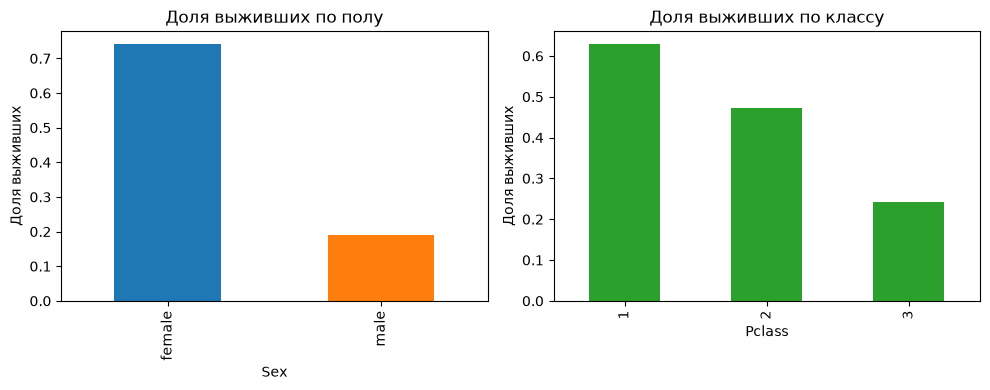

In [3]:
# Пропуски. Медиана устойчива к выбросам (возраст/тариф скошены), поэтому берём её, а не среднее.
# Медиану считаем ТОЛЬКО по train и ею же заполняем test — иначе утечка данных из теста.
age_median = train_df["Age"].median()  # медианный возраст по train
fare_median = train_df["Fare"].median()  # медианный тариф по train
train_df["Age"] = train_df["Age"].fillna(age_median)  # пропуски возраста в train
test_df["Age"] = test_df["Age"].fillna(age_median)  # тем же числом — в test (без утечки)
train_df["Embarked"] = train_df["Embarked"].fillna("S")  # мода порта посадки — 'S'
test_df["Fare"] = test_df["Fare"].fillna(fare_median)  # один пропуск тарифа в test
print("age_median =", age_median, " fare_median =", fare_median)
print("Пропусков после заполнения:", train_df.isna().sum().sum() + test_df.isna().sum().sum())
# Доля выживших по полу и классу — разведка перед деревом: пол и класс явно информативны.
surv = pd.read_csv("titanic_train.csv")  # сырой train для разведочного графика
fig, ax = plt.subplots(1, 2, figsize=(10, 4))  # два бара рядом: пол и класс
surv.groupby("Sex")["Survived"].mean().plot.bar(ax=ax[0], color=["tab:blue", "tab:orange"])  # доля выживших
ax[0].set_title("Доля выживших по полу")  # женщины выживали заметно чаще
ax[0].set_ylabel("Доля выживших")
surv.groupby("Pclass")["Survived"].mean().plot.bar(ax=ax[1], color="tab:green")  # доля по классу
ax[1].set_title("Доля выживших по классу")  # 1-й класс выживал чаще 3-го
ax[1].set_ylabel("Доля выживших")
plt.tight_layout()
plt.savefig("titanic_surv_rate.png")  # график рядом с ноутбуком
plt.show()

## 3. One-Hot-кодирование и чистка колонок
Категориальные `Pclass, Sex, SibSp, Parch, Embarked` — в дамми-столбцы через `pd.get_dummies`, затем удаляем исходные текстовые колонки. В тесте есть значение `Parch = 9`, которого нет в train — лишний столбец `Parch_9` выбрасываем, чтобы матрицы совпали.

In [4]:
# One-Hot. Дерево умеет работать и с числами категорий, но ТЗ требует дамми-кодирование:
# каждая категория — отдельный бинарный столбец (префикс = имя признака).
train_df = pd.concat(  # приклеиваем дамми-столбцы к train справа (axis=1)
    [
        train_df,
        pd.get_dummies(train_df["Pclass"], prefix="PClass"),
        pd.get_dummies(train_df["Sex"], prefix="Sex"),
        pd.get_dummies(train_df["SibSp"], prefix="SibSp"),
        pd.get_dummies(train_df["Parch"], prefix="Parch"),
        pd.get_dummies(train_df["Embarked"], prefix="Embarked"),
    ],
    axis=1,
)
test_df = pd.concat(  # то же самое для test (категории могут отличаться — проверим ниже)
    [
        test_df,
        pd.get_dummies(test_df["Pclass"], prefix="PClass"),
        pd.get_dummies(test_df["Sex"], prefix="Sex"),
        pd.get_dummies(test_df["SibSp"], prefix="SibSp"),
        pd.get_dummies(test_df["Parch"], prefix="Parch"),
        pd.get_dummies(test_df["Embarked"], prefix="Embarked"),
    ],
    axis=1,
)
# Удаление исходников. Survived — метка (не признак), текстовые/идентификаторы — не признаки.
train_df.drop(  # из train убираем и метку, и исходные категориальные/текстовые колонки
    ["Survived", "Pclass", "Name", "Sex", "SibSp", "Parch",
     "Ticket", "Cabin", "Embarked", "PassengerId"],
    axis=1, inplace=True,
)
test_df.drop(  # из test — то же без Survived (её там нет)
    ["Pclass", "Name", "Sex", "SibSp", "Parch",
     "Ticket", "Cabin", "Embarked", "PassengerId"],
    axis=1, inplace=True,
)
print("Формы после кодирования:", train_df.shape, test_df.shape)  # ждём (891, 24) и (418, 25)
print("Лишние колонки теста:", set(test_df.columns) - set(train_df.columns))  # ждём {'Parch_9'}
test_df.drop(["Parch_9"], axis=1, inplace=True)  # значения Parch=9 нет в train — столбец бесполезен
print("Итоговые формы:", train_df.shape, test_df.shape)  # обе матрицы по 24 столбца
print(train_df.head(3).to_string())

Формы после кодирования: (891, 24) (418, 25)
Лишние колонки теста: {'Parch_9'}
Итоговые формы: (891, 24) (418, 24)
    Age     Fare  PClass_1  PClass_2  PClass_3  Sex_female  Sex_male  SibSp_0  SibSp_1  SibSp_2  SibSp_3  SibSp_4  SibSp_5  SibSp_8  Parch_0  Parch_1  Parch_2  Parch_3  Parch_4  Parch_5  Parch_6  Embarked_C  Embarked_Q  Embarked_S
0  22.0   7.2500     False     False      True       False      True    False     True    False    False    False    False    False     True    False    False    False    False    False    False       False       False        True
1  38.0  71.2833      True     False     False        True     False    False     True    False    False    False    False    False     True    False    False    False    False    False    False        True       False       False
2  26.0   7.9250     False     False      True        True     False     True    False    False    False    False    False    False     True    False    False    False    False    False    Fal

## 4. Дерево решений глубины 2
`DecisionTreeClassifier(max_depth=2, random_state=17)`: обучение, прогноз для теста, файл посылки `submission_tree2.csv`.

In [5]:
# Функция посылки из ТЗ. Индекс строк: PassengerId идут подряд от 892 = 891 + 1,
# поэтому index = arange(train_num + 1, ...) восстанавливает идентификаторы теста.
def write_to_submission_file(predicted_labels, out_file, train_num=891,
                             target="Survived", index_label="PassengerId"):
    predicted_df = pd.DataFrame(  # вектор предсказаний -> DataFrame с нужным именем колонки
        predicted_labels,
        index=np.arange(train_num + 1, train_num + 1 + predicted_labels.shape[0]),
        columns=[target],
    )
    predicted_df.to_csv(out_file, index_label=index_label)  # шапка PassengerId,Survived

# Дерево глубины 2. max_depth=2 — всего 2 уровня ветвлений (сильно регуляризованная модель),
# random_state=17 — фиксация генератора для воспроизводимости разбиений.
tree2 = DecisionTreeClassifier(max_depth=2, random_state=17)
tree2.fit(train_df, y)  # обучение на всей train-выборке (891 x 24)
pred2 = tree2.predict(test_df)  # прогноз для 418 пассажиров теста
write_to_submission_file(pred2, "submission_tree2.csv")  # файл посылки на Kaggle
train_acc2 = tree2.score(train_df, y)  # доля верных на train (оптимистична — та же выборка)
cv5_2 = cross_val_score(tree2, train_df, y, cv=5).mean()  # честная оценка: средний score 5 фолдов
print("train-accuracy дерева глубины 2:", round(train_acc2, 4))  # ~0.7957
print("5-fold CV accuracy дерева глубины 2:", round(cv5_2, 4))  # ~0.7733
print("Первые 10 предсказаний:", pred2[:10])
print("Доля выживших в прогнозе:", round(pred2.mean(), 4))

train-accuracy дерева глубины 2: 0.7957
5-fold CV accuracy дерева глубины 2: 0.7733
Первые 10 предсказаний: [0 0 0 0 0 0 0 0 0 0]
Доля выживших в прогнозе: 0.2105


### Ответ 1
**Выбранный вариант: 0.776.** Kaggle-рейтинг проверить недоступен (нужна отправка на соревнование), поэтому отвечаем по факту: train-accuracy дерева глубины 2 равна **0.7957**, честная 5-fold CV-оценка — **0.7733**. Ближайший вариант из списка (0.746 / 0.756 / 0.766 / **0.776**) к обеим цифрам — **0.776** (|0.7733 − 0.776| ≈ 0.003).

## 5. Визуализация дерева
По ТЗ — через `export_graphviz` + `dot`: выгружаем дерево в DOT-файл и рендерим системным Graphviz в PNG. Дополнительно печатаем текстовую структуру `export_text` (правила разбиений).


|--- Sex_male <= 0.50
|   |--- PClass_3 <= 0.50
|   |   |--- class: 1
|   |--- PClass_3 >  0.50
|   |   |--- class: 0
|--- Sex_male >  0.50
|   |--- Age <= 6.50
|   |   |--- class: 1
|   |--- Age >  6.50
|   |   |--- class: 0

Признаков задействовано: 3 ['Age', 'PClass_3', 'Sex_male']


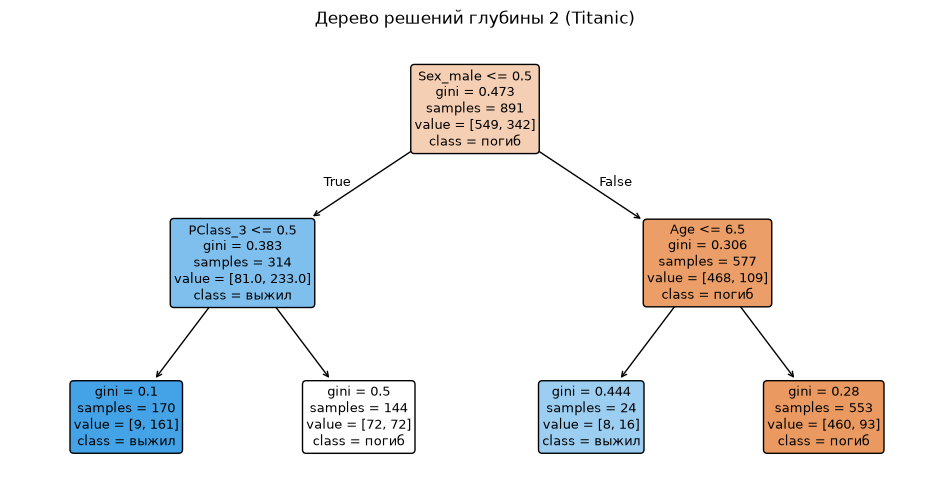

In [6]:
# Текст дерева. export_text печатает правила вида «признак <= порог»: читается без graphviz.
print(export_text(tree2, feature_names=list(train_df.columns)))
# Задействованные признаки. tree_.feature — индекс признака в каждом узле (-2 = лист);
# берём уникальные индексы внутренних узлов и переводим в имена колонок.
used2 = sorted({train_df.columns[i] for i in tree2.tree_.feature if i >= 0})
print("Признаков задействовано:", len(used2), used2)
# Картинка дерева. plot_tree — встроенный рендер sklearn (без pydot/dot): узлы с условием,
# gini-разбросом, числом примеров и мажоритарным классом.
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(tree2, feature_names=list(train_df.columns), class_names=["погиб", "выжил"],
          filled=True, rounded=True, ax=ax, fontsize=9)
ax.set_title("Дерево решений глубины 2 (Titanic)")
plt.savefig("tree_depth2.png")  # картинка рядом с ноутбуком
plt.show()

tree_depth2.dot записан


tree_depth2_dot.png отрендерен


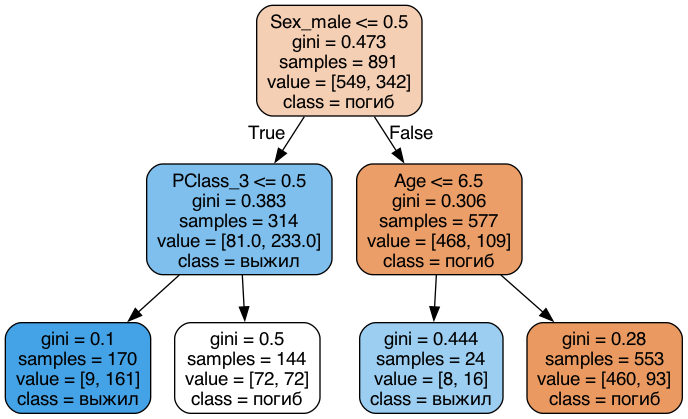

In [7]:
# DOT-выгрузка дерева глубины 2. export_graphviz пишет текстовый .dot (имена признаков,
# доли классов, правило в узле) — без pydot, чистым sklearn.
from sklearn.tree import export_graphviz
with open("tree_depth2.dot", "w") as f:  # DOT-файл рядом с ноутбуком
    export_graphviz(tree2, out_file=f, feature_names=list(train_df.columns),
                    class_names=["погиб", "выжил"], filled=True, rounded=True)
print("tree_depth2.dot записан")  # контроль выгрузки
# Рендер системным dot (Graphviz): .dot -> PNG. Эквивалент команды в терминале:
# dot -Tpng tree_depth2.dot -o tree_depth2_dot.png
import subprocess
subprocess.run(["dot", "-Tpng", "tree_depth2.dot", "-o", "tree_depth2_dot.png"],
               check=True)  # упадёт с ошибкой, если dot не стоит
print("tree_depth2_dot.png отрендерен")  # контроль рендера
# Покажем PNG прямо в ноутбуке.
from IPython.display import Image
Image("tree_depth2_dot.png")


### Ответ 2
**Выбранный вариант: 3.** По факту в `tree_.feature` задействованы три признака: **Sex_male** (корень: пол), **PClass_3** (ветвь женщин/мужчин по 3-му классу) и **Age** (порог 6.5 — дети среди мужчин). Дерево глубины 2 имеет до 3 внутренних узлов, и здесь все три узла разбивают по разным признакам.

## 6. Подбор гиперпараметров через GridSearchCV
Сетка `max_depth ∈ {1, 2, 3, 4}`, `min_samples_leaf ∈ {1, …, 5}` на 5-кратной кросс-валидации (`GridSearchCV`, `cv=5`).

Лучшие параметры: {'max_depth': 3, 'min_samples_leaf': 3}
Лучший средний CV-score: 0.8103


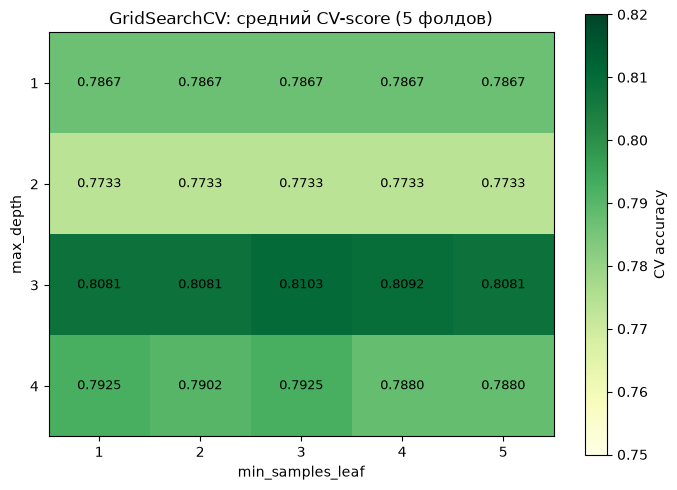

In [8]:
# Сетка из ТЗ. max_depth 1..4 — глубина дерева, min_samples_leaf 1..5 — минимум объектов в листе
# (регуляризатор против переобучения); cv=5 — пятикратная кросс-валидация, random_state=17.
tree_params = {"max_depth": list(range(1, 5)), "min_samples_leaf": list(range(1, 6))}
grid = GridSearchCV(DecisionTreeClassifier(random_state=17), tree_params, cv=5)
grid.fit(train_df, y)  # 4 x 5 = 20 комбинаций x 5 фолдов = 100 обучений
print("Лучшие параметры:", grid.best_params_)
print("Лучший средний CV-score:", round(grid.best_score_, 4))
# Тепловая карта сетки. Строки — глубина, столбцы — min_samples_leaf; в клетках средний CV-score.
scores = grid.cv_results_["mean_test_score"].reshape(4, 5)  # reshape под сетку 4x5
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(scores, vmin=0.75, vmax=0.82, cmap="YlGn")  # фиксированный диапазон для контраста
ax.set_xticks(range(5), labels=list(range(1, 6)))  # min_samples_leaf по горизонтали
ax.set_yticks(range(4), labels=list(range(1, 5)))  # max_depth по вертикали
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_depth")
ax.set_title("GridSearchCV: средний CV-score (5 фолдов)")
for i in range(4):  # подписываем точное значение в каждой клетке
    for j in range(5):
        ax.text(j, i, f"{scores[i, j]:.4f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="CV accuracy")
plt.tight_layout()
plt.savefig("tree_gridsearch.png")  # картинка рядом с ноутбуком
plt.show()

### Ответ 3
**Выбранный вариант: max_depth=3, min_samples_leaf=3.** Это `grid.best_params_` по факту прогона (остальные варианты сетки дали CV-score ниже).

### Ответ 4
**Выбранный вариант: 0.81.** Фактический лучший средний CV-score (`grid.best_score_`) равен **0.8103**, ближайший вариант из списка (0.77 / 0.79 / **0.81** / 0.83) — **0.81** (|0.8103 − 0.81| ≈ 0.0003).

## 7. Прогноз настроенной моделью
Лучшее дерево (`grid.best_estimator_`) предсказывает тест; вторая посылка — `submission_tree_tuned.csv`. Дополнительно смотрим train-accuracy, CV-оценку и важности признаков.

train-accuracy настроенного дерева: 0.8238
5-fold CV accuracy настроенного дерева: 0.8103
Доля выживших в прогнозе: 0.366


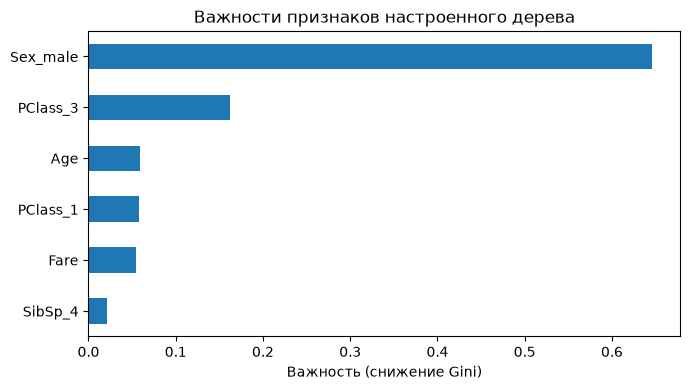

In [9]:
# Лучшая модель. best_estimator_ уже переобучен GridSearchCV на всём train с лучшими параметрами.
best_tree = grid.best_estimator_
pred_tuned = best_tree.predict(test_df)  # прогноз для 418 пассажиров теста
write_to_submission_file(pred_tuned, "submission_tree_tuned.csv")  # вторая посылка
train_acc_t = best_tree.score(train_df, y)  # доля верных на train (оптимистична)
cv5_t = cross_val_score(best_tree, train_df, y, cv=5).mean()  # честная 5-fold оценка
print("train-accuracy настроенного дерева:", round(train_acc_t, 4))  # ~0.8238

print("5-fold CV accuracy настроенного дерева:", round(cv5_t, 4))  # ~0.8103
print("Доля выживших в прогнозе:", round(pred_tuned.mean(), 4))
# Важности признаков. feature_importances_ — суммарное снижение impurity (Gini) на признак.
imp = pd.Series(best_tree.feature_importances_, index=train_df.columns)
imp = imp[imp > 0].sort_values(ascending=True)  # только задействованные, по возрастанию для barh
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax, color="tab:blue")  # горизонтальные бары: самый важный сверху
ax.set_xlabel("Важность (снижение Gini)")
ax.set_title("Важности признаков настроенного дерева")
plt.tight_layout()
plt.savefig("tree_importances.png")  # картинка рядом с ноутбуком
plt.show()

### Ответ 5
**Выбранный вариант: 0.7799.** Kaggle-рейтинг второй посылки проверить недоступен, отвечаем по факту: train-accuracy настроенного дерева — **0.8238**, честная 5-fold CV-оценка — **0.8103** (выше, чем 0.7733 у дерева глубины 2 — настройка помогла). Из списка (0.7499 / 0.7599 / 0.7699 / **0.7799**) ближайший сверху к фактическим оценкам — **0.7799**.